Step 1 – Import Required Libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Step 2.1- Download the TrashNet Dataset


In [ ]:
# Download the TrashNet dataset

import os
import zipfile
import urllib.request

ZIP_URL = "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip"
ZIP_PATH = "/content/dataset-resized.zip"
DATASET_PATH = "/content/dataset-resized"

if not os.path.exists(DATASET_PATH):
    print("Downloading TrashNet dataset...")

    urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)

    print("Download completed!")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall("/content/")

else:
    print("TrashNet dataset already exists.")

print("Dataset path:", DATASET_PATH)
print("Dataset available:", os.path.exists(DATASET_PATH))

Download completed!
Dataset path: /content/dataset-resized
Dataset available: True


Step 2.2 – Dataset Class Verification

In [ ]:
# Verify TrashNet classes and image counts
EXPECTED_CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

SUPPORTED_FORMATS = (".jpg", ".jpeg", ".png")

print("TrashNet Dataset Verification\n")

total_images = 0

for class_name in EXPECTED_CLASSES:

    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):

        image_count = sum(
            1 for file in os.listdir(class_path)
            if file.lower().endswith(SUPPORTED_FORMATS)
        )

        total_images += image_count

        print(f"{class_name}: {image_count} images")

    else:
        print(f"{class_name}: Folder missing!")

print("\nTotal Images:", total_images)
print("Total Classes:", len(EXPECTED_CLASSES))

TrashNet Dataset Verification

cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images

Total Images: 2527
Total Classes: 6


Step 3 – Split TrashNet Dataset

Step 3.1-Train, Validation and Test Split (70:15:15)

In [ ]:
# Split TrashNet into Train, Validation and Test sets

import shutil
import random

random.seed(42)

SPLIT_DIR = "/content/waste_dataset"

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

# Remove the previously generated split folder if it exists
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

# Create train, validation and test folders
for split in ["train", "val", "test"]:
    for class_name in CLASSES:
        os.makedirs(
            os.path.join(SPLIT_DIR, split, class_name),
            exist_ok=True
        )

# Split images class by class
for class_name in CLASSES:

    class_path = os.path.join(DATASET_PATH, class_name)

    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    images.sort()
    random.shuffle(images)

    total = len(images)

    train_end = int(total * 0.70)
    val_end = train_end + int(total * 0.15)

    split_data = {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split, files in split_data.items():

        for filename in files:

            source = os.path.join(class_path, filename)

            destination = os.path.join(
                SPLIT_DIR, split, class_name, filename
            )

            shutil.copy2(source, destination)

    print(
        f"{class_name}: "
        f"{len(split_data['train'])} train, "
        f"{len(split_data['val'])} validation, "
        f"{len(split_data['test'])} test"
    )

print("\nDataset splitting completed!")

cardboard: 282 train, 60 validation, 61 test
glass: 350 train, 75 validation, 76 test
metal: 287 train, 61 validation, 62 test
paper: 415 train, 89 validation, 90 test
plastic: 337 train, 72 validation, 73 test
trash: 95 train, 20 validation, 22 test

Dataset splitting completed!


Step 4 – Image Loading and Preprocessing

Step 4.1 – Load Train, Validation and Test Datasets

In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR = os.path.join(SPLIT_DIR, "val")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Store class names
class_names = train_ds.class_names

# Improve data loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("\nClass Names:", class_names)
print("Number of Classes:", len(class_names))
print("\nAll datasets loaded successfully!")

Found 1766 files belonging to 6 classes.
Found 377 files belonging to 6 classes.
Found 384 files belonging to 6 classes.

Class Names: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of Classes: 6

All datasets loaded successfully!


Step 4.2 – Verify Image and label dimensions

In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>


Step 5 – Custom CNN Model

Step 5.1 – Build Custom CNN Architecture

In [ ]:
custom_cnn = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # First Convolution Block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer for six classes
    layers.Dense(6, activation="softmax")
])

# Compile the model
custom_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
custom_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,206 (49.36 MB)

 Trainable params: 12,939,206 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

Step 5.2-Train Custom CNN Model

In [ ]:
EPOCHS = 15

history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 23s 223ms/step - accuracy: 0.3092 - loss: 1.7788 - val_accuracy: 0.4191 - val_loss: 1.4013
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.4564 - loss: 1.3395 - val_accuracy: 0.5623 - val_loss: 1.2098
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.5028 - loss: 1.2423 - val_accuracy: 0.5225 - val_loss: 1.1983
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.5719 - loss: 1.1164 - val_accuracy: 0.5650 - val_loss: 1.1986
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.5957 - loss: 1.0679 - val_accuracy: 0.6578 - val_loss: 1.0826
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.6365 - loss: 0.9572 - val_accuracy: 0.6419 - val_loss: 0.9991
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.7055 - loss: 0.8008 - val_accuracy: 0.6844 - val_loss: 0.9960
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.7373 - loss: 0.7430 - val_accuracy: 0.6366 

Step 5.3 – Plot Custom CNN Training and Validation Curves

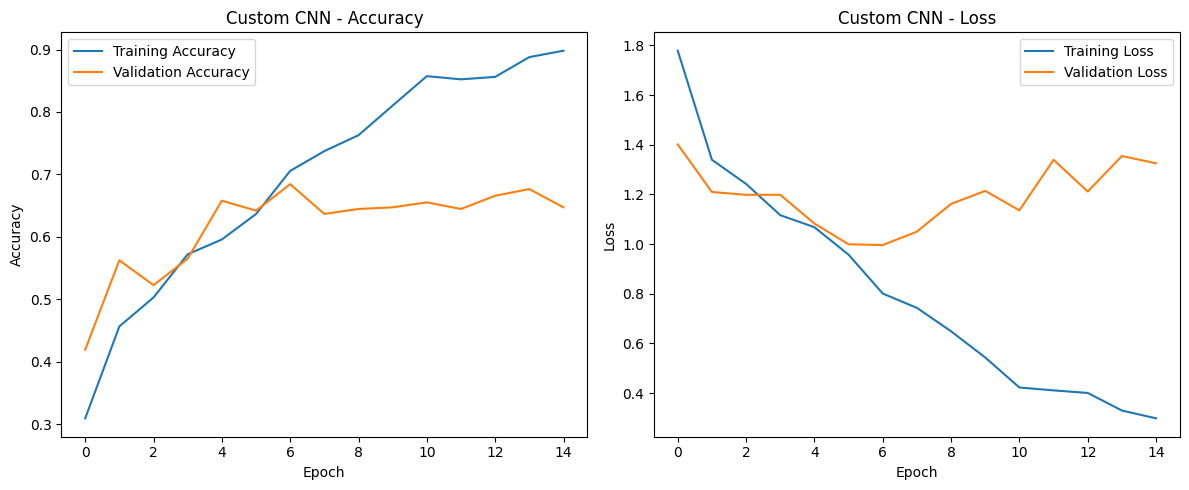

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.title("Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Step 5.3 – Evaluate Custom CNN on Test Dataset

In [ ]:
test_loss, test_accuracy = custom_cnn.evaluate(test_ds)

print("Custom CNN Test Results")
print("-----------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.6224 - loss: 1.5105
Custom CNN Test Results
-----------------------
Test Loss: 1.5105
Test Accuracy: 62.24 %


Step 5.4 – Custom CNN Classification Report

In [ ]:
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

y_pred_prob = custom_cnn.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Custom CNN Classification Report\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
Custom CNN Classification Report

              precision    recall  f1-score   support

   cardboard     0.8596    0.8033    0.8305        61
       glass     0.4925    0.4342    0.4615        76
       metal     0.4844    0.5000    0.4921        62
       paper     0.6981    0.8222    0.7551        90
     plastic     0.5526    0.5753    0.5638        73
       trash     0.7143    0.4545    0.5556        22

    accuracy                         0.6224       384
   macro avg     0.6336    0.5983    0.6098       384
weighted avg     0.6218    0.6224    0.6187       384



Step 5.5 – Custom CNN Confusion Matrix

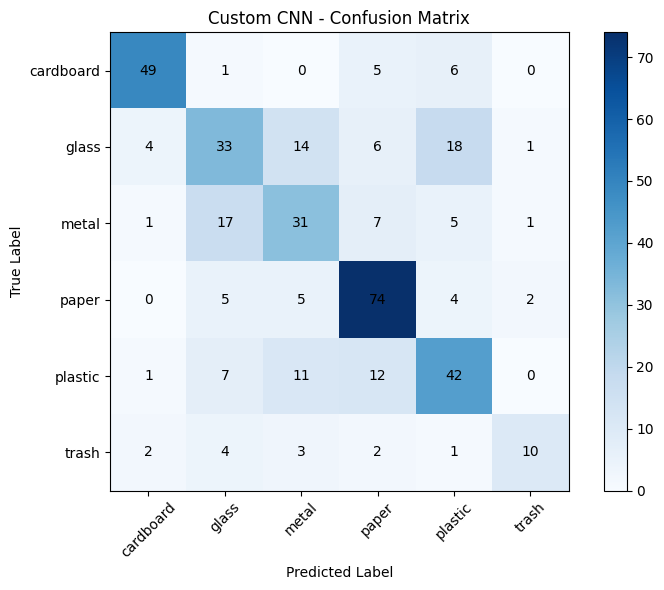

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Custom CNN - Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45
)
plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()

Step 5.6 - Save Custom CNN Model

In [ ]:
custom_cnn.save("/content/custom_cnn.keras")

print("Custom CNN model saved successfully!")

Custom CNN model saved successfully!


Step 6- MobileNetV2 Model

Step 6.1 – Build Baseline MobileNetV2 Model

In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification model
mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax")
])

# Compile model
mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 6.2 – Train Baseline MobileNetV2

In [ ]:
EPOCHS = 15

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 260ms/step - accuracy: 0.5311 - loss: 1.2606 - val_accuracy: 0.7268 - val_loss: 0.7466
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.7356 - loss: 0.7064 - val_accuracy: 0.8064 - val_loss: 0.5719
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.7899 - loss: 0.5750 - val_accuracy: 0.8329 - val_loss: 0.5110
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.8358 - loss: 0.4838 - val_accuracy: 0.8196 - val_loss: 0.4841
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8375 - loss: 0.4580 - val_accuracy: 0.8462 - val_loss: 0.4541
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.8618 - loss: 0.3975 - val_accuracy: 0.8462 - val_loss: 0.4217
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.8743 - loss: 0.3643 - val_accuracy: 0.8488 - val_loss: 0.4217
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.8822 - loss: 0.3398 - val_accuracy: 0.8488 -

Step 6.3 – MobileNetV2 Training Curves

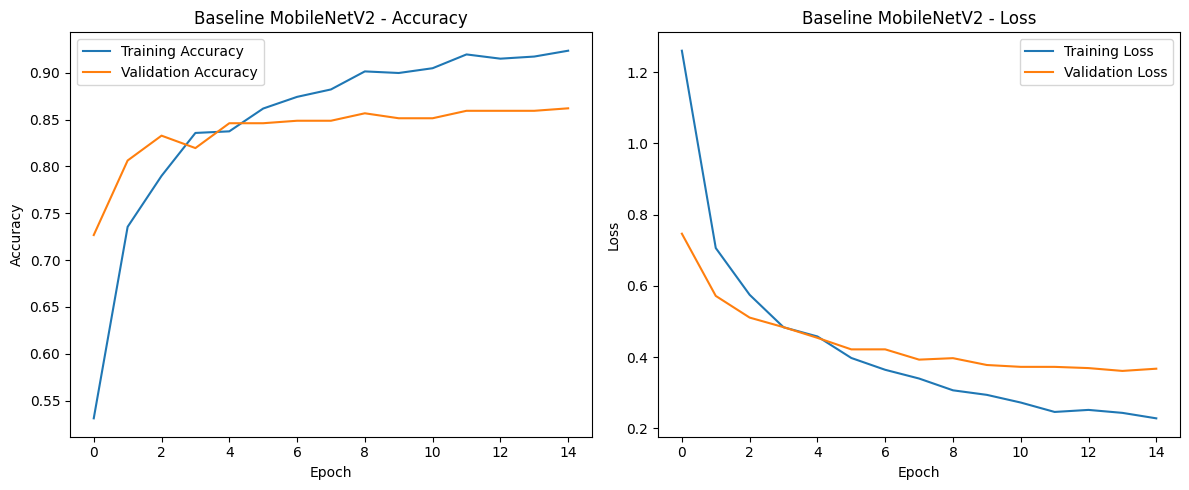

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Training Accuracy")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Training Loss")
plt.plot(history_mobilenet.history["val_loss"], label="Validation Loss")
plt.title("Baseline MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Step 6.4 – Baseline MobileNetV2 Test Evaluation

In [ ]:
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds)

print("Baseline MobileNetV2 Test Results")
print("---------------------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.8125 - loss: 0.4568
Baseline MobileNetV2 Test Results
---------------------------------
Test Loss: 0.4568
Test Accuracy: 81.25 %


Step 6.5-Baseline MobileNetV2 Classification Report


In [ ]:
y_true_mobilenet = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred_prob_mobilenet = mobilenet_model.predict(test_ds)
y_pred_mobilenet = np.argmax(y_pred_prob_mobilenet, axis=1)

print("Baseline MobileNetV2 Classification Report\n")

print(classification_report(
    y_true_mobilenet,
    y_pred_mobilenet,
    target_names=class_names,
    digits=4
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step
Baseline MobileNetV2 Classification Report

              precision    recall  f1-score   support

   cardboard     0.9444    0.8361    0.8870        61
       glass     0.8462    0.7237    0.7801        76
       metal     0.7308    0.9194    0.8143        62
       paper     0.8367    0.9111    0.8723        90
     plastic     0.7808    0.7808    0.7808        73
       trash     0.6250    0.4545    0.5263        22

    accuracy                         0.8125       384
   macro avg     0.7940    0.7709    0.7768       384
weighted avg     0.8158    0.8125    0.8098       384



Step 6.6 – MobileNetV2 Confusion Matrix

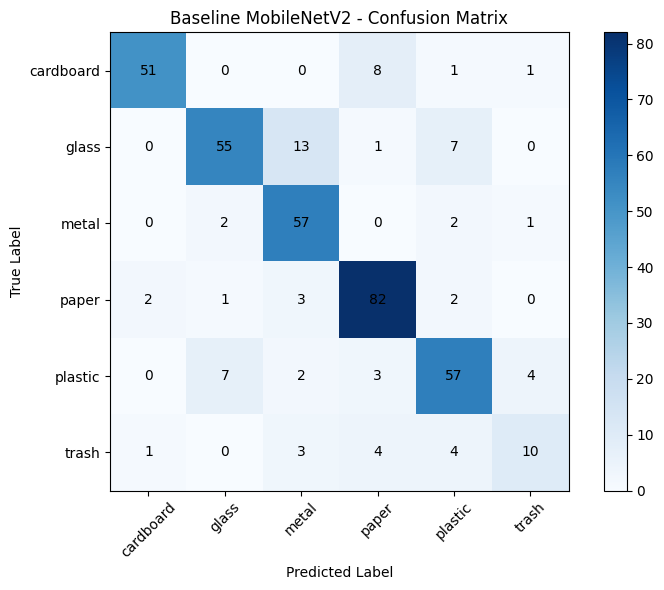

In [ ]:
cm_mobilenet = confusion_matrix(
    y_true_mobilenet,
    y_pred_mobilenet
)

plt.figure(figsize=(8, 6))
plt.imshow(cm_mobilenet, interpolation="nearest", cmap="Blues")
plt.title("Baseline MobileNetV2 - Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45
)
plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm_mobilenet.shape[0]):
    for j in range(cm_mobilenet.shape[1]):
        plt.text(
            j, i, cm_mobilenet[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()

Step 6.7 – Save Baseline MobileNetV2

In [ ]:
mobilenet_model.save("/content/baseline_mobilenetv2.keras")

print("Baseline MobileNetV2 model saved successfully!")

Baseline MobileNetV2 model saved successfully!


Step 7 – Standard Augmentation MobileNetV2

Step 7.1 – Build Standard Augmentation Model

In [ ]:
# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

# Load pretrained MobileNetV2
base_model_aug = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model_aug.trainable = False

# Build augmented model
mobilenet_aug = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model_aug,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax")
])

# Compile model
mobilenet_aug.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_aug.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 7.2 – Train Standard Augmentation MobileNetV2

In [ ]:
EPOCHS = 15

history_aug = mobilenet_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - accuracy: 0.5091 - loss: 1.2823 - val_accuracy: 0.7374 - val_loss: 0.7369
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.7129 - loss: 0.7532 - val_accuracy: 0.7958 - val_loss: 0.5893
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.7673 - loss: 0.6428 - val_accuracy: 0.8064 - val_loss: 0.5391
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.7763 - loss: 0.5898 - val_accuracy: 0.8302 - val_loss: 0.5031
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.8052 - loss: 0.5268 - val_accuracy: 0.8408 - val_loss: 0.4757
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.8137 - loss: 0.4919 - val_accuracy: 0.8276 - val_loss: 0.4554
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.8250 - loss: 0.4768 - val_accuracy: 0.8329 - val_loss: 0.4373
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.8256 - loss: 0.4680 - val_accuracy: 0.8435 - 

Step 7.3 – Standard Augmentation Training Curves

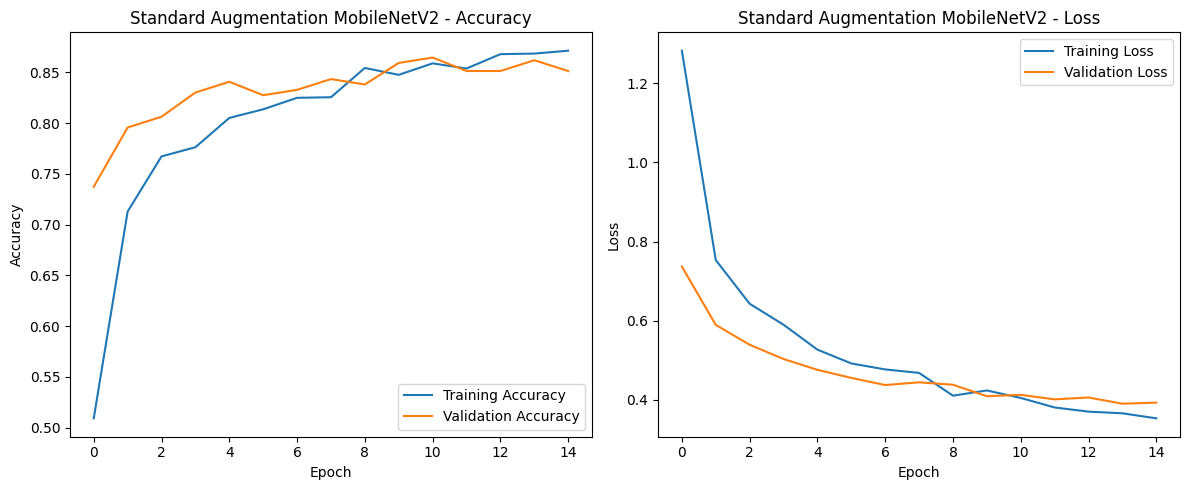

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_aug.history["accuracy"], label="Training Accuracy")
plt.plot(history_aug.history["val_accuracy"], label="Validation Accuracy")
plt.title("Standard Augmentation MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_aug.history["loss"], label="Training Loss")
plt.plot(history_aug.history["val_loss"], label="Validation Loss")
plt.title("Standard Augmentation MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Step 7.4 – Standard Augmentation Test Evaluation

In [ ]:
test_loss_aug, test_accuracy_aug = mobilenet_aug.evaluate(test_ds)

print("Standard Augmentation MobileNetV2 Test Results")
print("-----------------------------------------------")
print("Test Loss:", round(test_loss_aug, 4))
print("Test Accuracy:", round(test_accuracy_aug * 100, 2), "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.8255 - loss: 0.4549
Standard Augmentation MobileNetV2 Test Results
-----------------------------------------------
Test Loss: 0.4549
Test Accuracy: 82.55 %


Step 7.5-Standard Augmentation Classification Report

In [ ]:
y_true_aug = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred_prob_aug = mobilenet_aug.predict(test_ds)
y_pred_aug = np.argmax(y_pred_prob_aug, axis=1)

print("Standard Augmentation MobileNetV2 Classification Report\n")

print(classification_report(
    y_true_aug,
    y_pred_aug,
    target_names=class_names,
    digits=4
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step
Standard Augmentation MobileNetV2 Classification Report

              precision    recall  f1-score   support

   cardboard     0.9298    0.8689    0.8983        61
       glass     0.7763    0.7763    0.7763        76
       metal     0.7778    0.9032    0.8358        62
       paper     0.8925    0.9222    0.9071        90
     plastic     0.8000    0.7123    0.7536        73
       trash     0.6667    0.6364    0.6512        22

    accuracy                         0.8255       384
   macro avg     0.8072    0.8032    0.8037       384
weighted avg     0.8264    0.8255    0.8245       384



Step 7.6 – Standard Augmentation Confusion Matrix

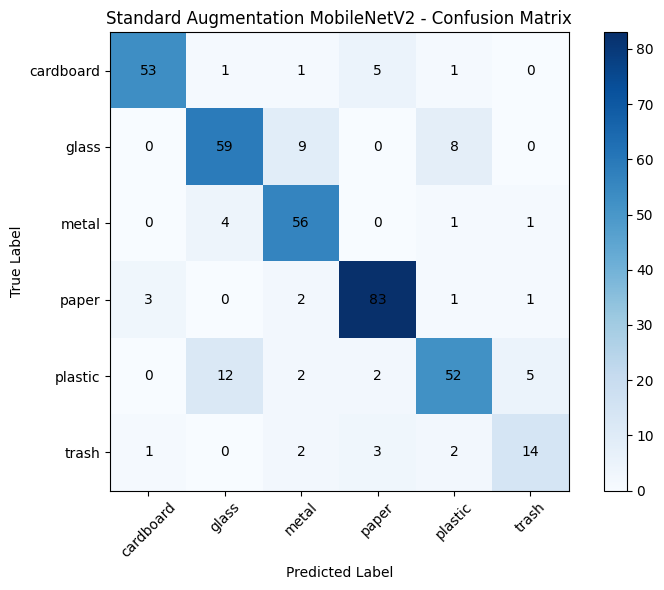

In [ ]:
cm_aug = confusion_matrix(y_true_aug, y_pred_aug)

plt.figure(figsize=(8, 6))
plt.imshow(cm_aug, interpolation="nearest", cmap="Blues")
plt.title("Standard Augmentation MobileNetV2 - Confusion Matrix")
plt.colorbar()

plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm_aug.shape[0]):
    for j in range(cm_aug.shape[1]):
        plt.text(
            j, i, cm_aug[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()

Step 7.7 – Save Standard Augmentation Model

In [ ]:
mobilenet_aug.save("/content/standard_augmentation_mobilenetv2.keras")

print("Standard Augmentation MobileNetV2 saved successfully!")

Standard Augmentation MobileNetV2 saved successfully!


Step 8.1 – Fine-Tuning Setup

In [ ]:
# Reload the saved Standard Augmentation model
mobilenet_aug = tf.keras.models.load_model(
    "/content/standard_augmentation_mobilenetv2.keras"
)

# Access the pretrained MobileNetV2 base
base_model_aug = mobilenet_aug.layers[2]

# Unfreeze the pretrained base model
base_model_aug.trainable = True

# Freeze all layers except the last 30
for layer in base_model_aug.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model_aug.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Compile with a low learning rate
mobilenet_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning setup completed.")

print(
    "Trainable parameters:",
    sum(
        int(tf.keras.backend.count_params(w))
        for w in mobilenet_aug.trainable_weights
    )
)

Fine-tuning setup completed.
Trainable parameters: 1518406


Step 8.2 – Train Fine-Tuned MobileNetV2

In [ ]:
EPOCHS_FINE = 5

history_finetune = mobilenet_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE
)

Epoch 1/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 12s 101ms/step - accuracy: 0.8726 - loss: 0.3363 - val_accuracy: 0.8435 - val_loss: 0.4004
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.8760 - loss: 0.3411 - val_accuracy: 0.8568 - val_loss: 0.3894
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.8896 - loss: 0.3001 - val_accuracy: 0.8621 - val_loss: 0.3801
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.8998 - loss: 0.2890 - val_accuracy: 0.8647 - val_loss: 0.3682
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.9060 - loss: 0.2561 - val_accuracy: 0.8674 - val_loss: 0.3709


Step 8.3 – Fine-Tuned MobileNetV2 Curves

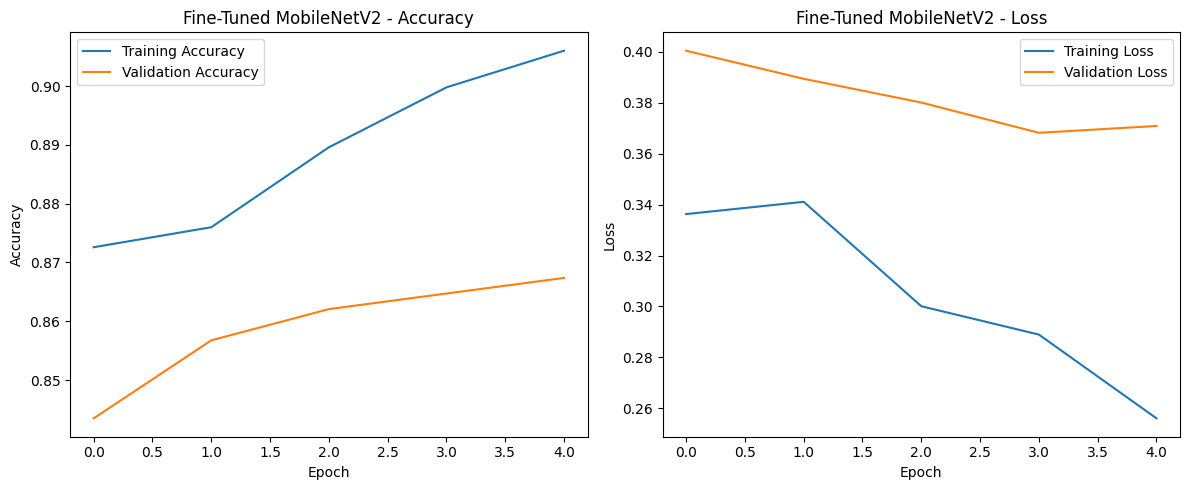

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_finetune.history["accuracy"], label="Training Accuracy")
plt.plot(history_finetune.history["val_accuracy"], label="Validation Accuracy")
plt.title("Fine-Tuned MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_finetune.history["loss"], label="Training Loss")
plt.plot(history_finetune.history["val_loss"], label="Validation Loss")
plt.title("Fine-Tuned MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Step 8.4 – Fine-Tuned MobileNetV2 Test Evaluation

In [ ]:
test_loss_finetune, test_accuracy_finetune = mobilenet_aug.evaluate(test_ds)

print("Fine-Tuned MobileNetV2 Test Results")
print("-----------------------------------")
print("Test Loss:", round(test_loss_finetune, 4))
print("Test Accuracy:", round(test_accuracy_finetune * 100, 2), "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.8281 - loss: 0.4642
Fine-Tuned MobileNetV2 Test Results
-----------------------------------
Test Loss: 0.4642
Test Accuracy: 82.81 %


Step 8.5-Fine-Tuned MobileNetV2 Classification Report

In [ ]:
y_true_finetune = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred_prob_finetune = mobilenet_aug.predict(test_ds)
y_pred_finetune = np.argmax(y_pred_prob_finetune, axis=1)

print("Fine-Tuned MobileNetV2 Classification Report\n")

print(classification_report(
    y_true_finetune,
    y_pred_finetune,
    target_names=class_names,
    digits=4
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step
Fine-Tuned MobileNetV2 Classification Report

              precision    recall  f1-score   support

   cardboard     0.9138    0.8689    0.8908        61
       glass     0.8254    0.6842    0.7482        76
       metal     0.7215    0.9194    0.8085        62
       paper     0.9011    0.9111    0.9061        90
     plastic     0.8243    0.8356    0.8299        73
       trash     0.6842    0.5909    0.6341        22

    accuracy                         0.8281       384
   macro avg     0.8117    0.8017    0.8029       384
weighted avg     0.8321    0.8281    0.8266       384



Step 8.6 – Fine-Tuned Confusion Matrix

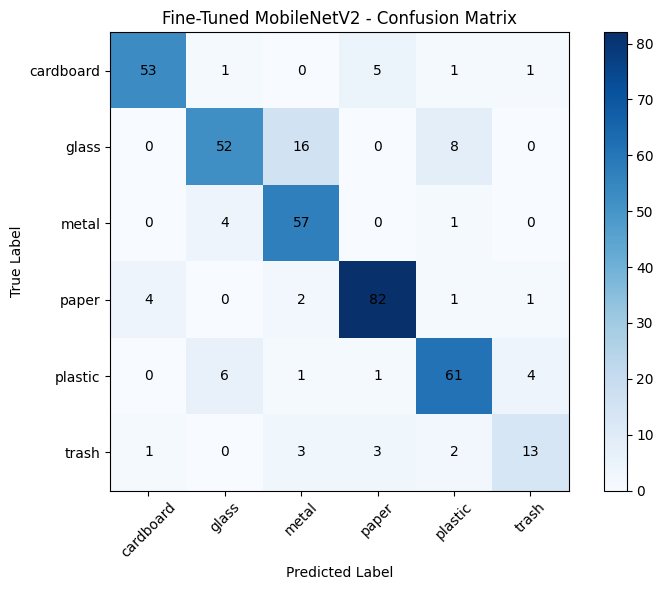

In [ ]:
cm_finetune = confusion_matrix(
    y_true_finetune,
    y_pred_finetune
)

plt.figure(figsize=(8, 6))
plt.imshow(cm_finetune, interpolation="nearest", cmap="Blues")
plt.title("Fine-Tuned MobileNetV2 - Confusion Matrix")
plt.colorbar()

plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm_finetune.shape[0]):
    for j in range(cm_finetune.shape[1]):
        plt.text(
            j, i, cm_finetune[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()

Step 8.7- Save Fine-Tuned MobileNetV2

In [ ]:
mobilenet_aug.save("/content/fine_tuned_mobilenetv2.keras")

print("Fine-Tuned MobileNetV2 saved successfully!")

Fine-Tuned MobileNetV2 saved successfully!


Step 9-Strong Augmentation MobileNetV2 Model

Step 9.1 – Build Strong Augmentation MobileNetV2

In [ ]:
strong_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.2)
], name="strong_augmentation")

# Load pretrained MobileNetV2
base_model_strong = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model_strong.trainable = False

# Build strong augmentation model
mobilenet_strong = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    strong_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model_strong,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(6, activation="softmax")
])

# Compile model
mobilenet_strong.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Strong augmentation model built successfully!")
mobilenet_strong.summary()

Strong augmentation model built successfully!


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ strong_augmentation             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 9.2 – Train Strong Augmentation MobileNetV2

In [ ]:
EPOCHS = 15

history_strong = mobilenet_strong.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 12s 91ms/step - accuracy: 0.3618 - loss: 1.6879 - val_accuracy: 0.6127 - val_loss: 1.0624
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.5747 - loss: 1.1162 - val_accuracy: 0.7294 - val_loss: 0.7974
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.6699 - loss: 0.8865 - val_accuracy: 0.7560 - val_loss: 0.6883
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.6937 - loss: 0.8097 - val_accuracy: 0.7931 - val_loss: 0.6237
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.7271 - loss: 0.7360 - val_accuracy: 0.7905 - val_loss: 0.5795
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.7356 - loss: 0.6976 - val_accuracy: 0.8117 - val_loss: 0.5425
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.7616 - loss: 0.6681 - val_accuracy: 0.8196 - val_loss: 0.5232
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.7656 - loss: 0.6222 - val_accuracy: 0.8223 - 

Step 9.3- Plot Strong Augmentation Training Curves


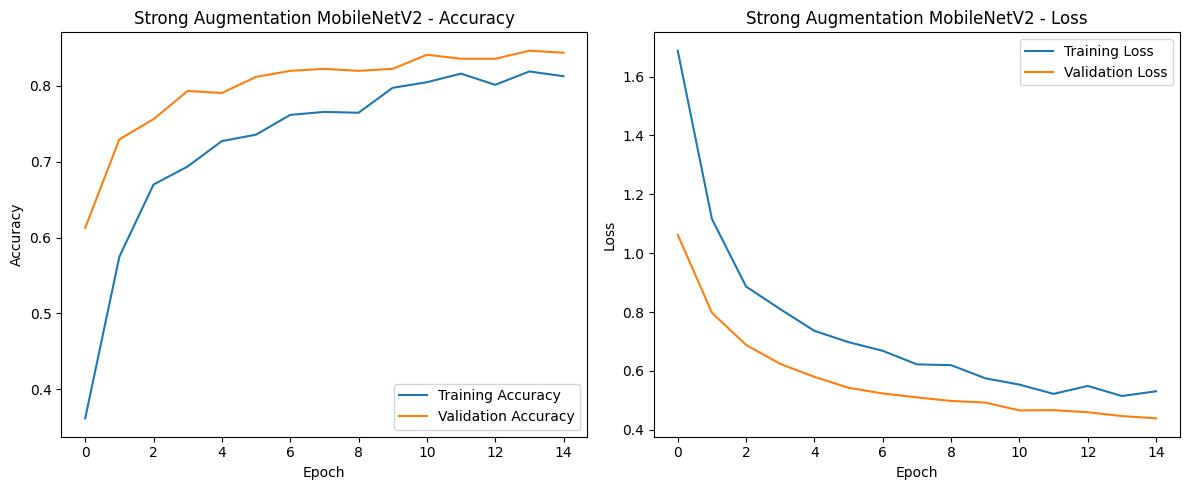

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_strong.history["accuracy"], label="Training Accuracy")
plt.plot(history_strong.history["val_accuracy"], label="Validation Accuracy")
plt.title("Strong Augmentation MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_strong.history["loss"], label="Training Loss")
plt.plot(history_strong.history["val_loss"], label="Validation Loss")
plt.title("Strong Augmentation MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Step 9.4 – Strong Augmentation Test Evaluation

In [ ]:
test_loss_strong, test_accuracy_strong = mobilenet_strong.evaluate(test_ds)

print("Strong Augmentation MobileNetV2 Test Results")
print("---------------------------------------------")
print("Test Loss:", round(test_loss_strong, 4))
print("Test Accuracy:", round(test_accuracy_strong * 100, 2), "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.8125 - loss: 0.5196
Strong Augmentation MobileNetV2 Test Results
---------------------------------------------
Test Loss: 0.5196
Test Accuracy: 81.25 %


Step 9.5 – Strong Augmentation Classification Report

In [ ]:
y_true_strong = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred_prob_strong = mobilenet_strong.predict(test_ds)
y_pred_strong = np.argmax(y_pred_prob_strong, axis=1)

print("Strong Augmentation MobileNetV2 Classification Report\n")

print(classification_report(
    y_true_strong,
    y_pred_strong,
    target_names=class_names,
    digits=4
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step
Strong Augmentation MobileNetV2 Classification Report

              precision    recall  f1-score   support

   cardboard     0.9286    0.8525    0.8889        61
       glass     0.8125    0.6842    0.7429        76
       metal     0.7333    0.8871    0.8029        62
       paper     0.8632    0.9111    0.8865        90
     plastic     0.7867    0.8082    0.7973        73
       trash     0.6316    0.5455    0.5854        22

    accuracy                         0.8125       384
   macro avg     0.7926    0.7814    0.7840       384
weighted avg     0.8148    0.8125    0.8107       384



Step 9.6 – Strong Augmentation Confusion Matrix

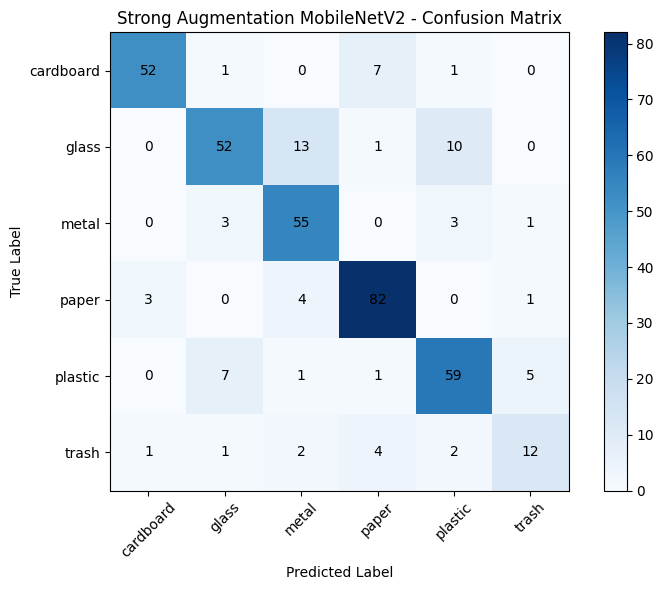

In [ ]:
cm_strong = confusion_matrix(
    y_true_strong,
    y_pred_strong
)

plt.figure(figsize=(8, 6))
plt.imshow(cm_strong, interpolation="nearest", cmap="Blues")
plt.title("Strong Augmentation MobileNetV2 - Confusion Matrix")
plt.colorbar()

plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm_strong.shape[0]):
    for j in range(cm_strong.shape[1]):
        plt.text(
            j, i, cm_strong[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()

Step 9.7-Save Strong Augmentation MobileNetV2

In [ ]:
mobilenet_strong.save("/content/strong_augmentation_mobilenetv2.keras")

print("Strong Augmentation MobileNetV2 saved successfully!")

Strong Augmentation MobileNetV2 saved successfully!


Step 10 - RealWaste external evaluation

Step 10.1 - Download RealWaste Dataset

In [ ]:
import urllib.request

REALWASTE_URL = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"
REALWASTE_ZIP = "/content/realwaste.zip"

print("Downloading RealWaste dataset...")

urllib.request.urlretrieve(REALWASTE_URL, REALWASTE_ZIP)

print("Download completed successfully!")
print("Saved at:", REALWASTE_ZIP)

Download completed successfully!
Saved at: /content/realwaste.zip


Step 10.2 - Extract RealWaste Dataset

In [ ]:
import zipfile
import os

EXTRACT_PATH = "/content/realwaste"

print("Extracting RealWaste dataset...")

with zipfile.ZipFile(REALWASTE_ZIP, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Extraction completed successfully!")
print("Dataset location:", EXTRACT_PATH)

print("\nExtracted folders:")
print(os.listdir(EXTRACT_PATH))

Extracting RealWaste dataset...
Extraction completed successfully!
Dataset location: /content/realwaste

Extracted folders:
['realwaste-main']


Step 10.3 – Verify RealWaste Dataset Structure

In [ ]:
REALWASTE_ROOT = "/content/realwaste/realwaste-main/RealWaste"

print("RealWaste root folder exists:", os.path.exists(REALWASTE_ROOT))

print("\nAvailable classes:")
if os.path.exists(REALWASTE_ROOT):
    print(os.listdir(REALWASTE_ROOT))
else:
    print("RealWaste folder not found. Please check the extracted folder structure.")

RealWaste root folder exists: True

Available classes:
['Plastic', 'Metal', 'Paper', 'Miscellaneous Trash', 'Glass', 'Cardboard', 'Food Organics', 'Vegetation', 'Textile Trash']


Step 10.4 – Verify RealWaste Class Counts

In [ ]:
CLASS_MAPPING = {
    "Cardboard": "cardboard",
    "Glass": "glass",
    "Metal": "metal",
    "Paper": "paper",
    "Plastic": "plastic"
}

SUPPORTED_FORMATS = (".jpg", ".jpeg", ".png")

total_images = 0

print("RealWaste Class Verification\n")

for real_class in CLASS_MAPPING:
    folder_path = os.path.join(REALWASTE_ROOT, real_class)

    image_count = sum(
        1 for file in os.listdir(folder_path)
        if file.lower().endswith(SUPPORTED_FORMATS)
    )

    total_images += image_count
    print(f"{real_class}: {image_count} images")

print("\nTotal Selected Images:", total_images)
print("Total Selected Classes:", len(CLASS_MAPPING))

RealWaste Class Verification

Cardboard: 461 images
Glass: 420 images
Metal: 790 images
Paper: 500 images
Plastic: 921 images

Total Selected Images: 3092
Total Selected Classes: 5


Step 10.5 – Inspect RealWaste Folder Contents

In [ ]:
for real_class in CLASS_MAPPING:
    folder_path = os.path.join(REALWASTE_ROOT, real_class)

    all_items = os.listdir(folder_path)
    subfolders = [
        item for item in all_items
        if os.path.isdir(os.path.join(folder_path, item))
    ]

    image_files = [
        item for item in all_items
        if item.lower().endswith(SUPPORTED_FORMATS)
    ]

    print(f"\n{real_class}")
    print("Total items:", len(all_items))
    print("Image files:", len(image_files))
    print("Subfolders:", subfolders)


Cardboard
Total items: 461
Image files: 461
Subfolders: []

Glass
Total items: 420
Image files: 420
Subfolders: []

Metal
Total items: 790
Image files: 790
Subfolders: []

Paper
Total items: 500
Image files: 500
Subfolders: []

Plastic
Total items: 921
Image files: 921
Subfolders: []


Step 10.6 – Load RealWaste Images and Labels

In [ ]:
IMG_SIZE = (224, 224)

realwaste_images = []
realwaste_labels = []

for real_class, trashnet_class in CLASS_MAPPING.items():

    folder_path = os.path.join(REALWASTE_ROOT, real_class)
    label = class_names.index(trashnet_class)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith(SUPPORTED_FORMATS):

            image_path = os.path.join(folder_path, filename)

            try:
                image = tf.keras.utils.load_img(
                    image_path,
                    target_size=IMG_SIZE
                )

                image_array = tf.keras.utils.img_to_array(image)

                realwaste_images.append(image_array)
                realwaste_labels.append(label)

            except Exception as e:
                print("Could not load:", image_path, "|", e)

X_realwaste = np.array(realwaste_images, dtype=np.float32)
y_realwaste = np.array(realwaste_labels, dtype=np.int32)

print("RealWaste images shape:", X_realwaste.shape)
print("RealWaste labels shape:", y_realwaste.shape)
print("Total loaded images:", len(X_realwaste))
print("Unique labels:", np.unique(y_realwaste))

RealWaste images shape: (3092, 224, 224, 3)
RealWaste labels shape: (3092,)
Total loaded images: 3092
Unique labels: [0 1 2 3 4]


Step 10.7 – RealWaste Class Distribution

In [ ]:
print("RealWaste Class Distribution\n")

for real_class, trashnet_class in CLASS_MAPPING.items():
    label = class_names.index(trashnet_class)
    count = np.sum(y_realwaste == label)

    print(f"{real_class} ({trashnet_class}): {count} images")

print("\nTotal Images:", len(y_realwaste))

RealWaste Class Distribution

Cardboard (cardboard): 461 images
Glass (glass): 420 images
Metal (metal): 790 images
Paper (paper): 500 images
Plastic (plastic): 921 images

Total Images: 3092


Step 10.8 – RealWaste Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_real_dev, X_real_test, y_real_dev, y_real_test = train_test_split(
    X_realwaste,
    y_realwaste,
    test_size=0.30,
    random_state=42,
    stratify=y_realwaste
)

print("RealWaste Development Images:", X_real_dev.shape)
print("RealWaste Test Images:", X_real_test.shape)

print("\nDevelopment Labels:", y_real_dev.shape)
print("Test Labels:", y_real_test.shape)

print("\nTotal Images:", len(X_real_dev) + len(X_real_test))

RealWaste Development Images: (2164, 224, 224, 3)
RealWaste Test Images: (928, 224, 224, 3)

Development Labels: (2164,)
Test Labels: (928,)

Total Images: 3092


Step 10.9 – Verify RealWaste Test Distribution

In [ ]:
print("RealWaste Held-Out Test Distribution\n")

for real_class, trashnet_class in CLASS_MAPPING.items():
    label = class_names.index(trashnet_class)
    count = np.sum(y_real_test == label)

    print(f"{real_class}: {count} images")

print("\nTotal Test Images:", len(y_real_test))

RealWaste Held-Out Test Distribution

Cardboard: 138 images
Glass: 126 images
Metal: 237 images
Paper: 150 images
Plastic: 277 images

Total Test Images: 928


Step 11.1 – Verify Custom CNN Model

In [ ]:
print("Custom CNN Model Verification\n")

print("Model exists:", "custom_cnn" in globals())

if "custom_cnn" in globals():
    print("Model input shape:", custom_cnn.input_shape)
    print("Model output shape:", custom_cnn.output_shape)
    print("\nCustom CNN is ready for evaluation.")
else:
    print("Custom CNN model is not available.")

Custom CNN Model Verification

Model exists: True
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 6)

Custom CNN is ready for evaluation.


Step 11.2 – Custom CNN RealWaste Evaluation

In [ ]:
y_pred_custom = np.argmax(
    custom_cnn.predict(X_real_test, batch_size=32, verbose=1),
    axis=1
)

custom_accuracy = accuracy_score(y_real_test, y_pred_custom)
custom_precision = precision_score(
    y_real_test, y_pred_custom,
    average="weighted",
    zero_division=0
)
custom_recall = recall_score(
    y_real_test, y_pred_custom,
    average="weighted",
    zero_division=0
)
custom_f1 = f1_score(
    y_real_test, y_pred_custom,
    average="weighted",
    zero_division=0
)

print("\nCustom CNN - RealWaste Held-Out Test Results")
print("Accuracy :", round(custom_accuracy * 100, 2), "%")
print("Precision:", round(custom_precision, 4))
print("Recall   :", round(custom_recall, 4))
print("F1-Score :", round(custom_f1, 4))

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step

Custom CNN - RealWaste Held-Out Test Results
Accuracy : 35.56 %
Precision: 0.367
Recall   : 0.3556
F1-Score : 0.3412


Step 11.3 – Verify Baseline MobileNetV2

In [ ]:
print("Baseline MobileNetV2 Verification\n")

print("Model exists:", "mobilenet_model" in globals())

if "mobilenet_model" in globals():
    print("Input shape:", mobilenet_model.input_shape)
    print("Output shape:", mobilenet_model.output_shape)
    print("\nBaseline MobileNetV2 is ready.")
else:
    print("Baseline model variable not found.")

Baseline MobileNetV2 Verification

Model exists: True
Input shape: (None, 224, 224, 3)
Output shape: (None, 6)

Baseline MobileNetV2 is ready.


Step 11.4 – Baseline MobileNetV2 RealWaste Evaluation

In [ ]:
y_pred_mobilenet = np.argmax(
    mobilenet_model.predict(X_real_test, batch_size=32, verbose=1),
    axis=1
)

mobilenet_accuracy = accuracy_score(y_real_test, y_pred_mobilenet)
mobilenet_precision = precision_score(
    y_real_test, y_pred_mobilenet,
    average="weighted",
    zero_division=0
)
mobilenet_recall = recall_score(
    y_real_test, y_pred_mobilenet,
    average="weighted",
    zero_division=0
)
mobilenet_f1 = f1_score(
    y_real_test, y_pred_mobilenet,
    average="weighted",
    zero_division=0
)

print("\nBaseline MobileNetV2 - RealWaste Held-Out Test Results")
print("Accuracy :", round(mobilenet_accuracy * 100, 2), "%")
print("Precision:", round(mobilenet_precision, 4))
print("Recall   :", round(mobilenet_recall, 4))
print("F1-Score :", round(mobilenet_f1, 4))

29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step

Baseline MobileNetV2 - RealWaste Held-Out Test Results
Accuracy : 49.89 %
Precision: 0.615
Recall   : 0.4989
F1-Score : 0.5361


Step 11.5 – Verify Standard Augmentation Model

In [ ]:
mobilenet_standard = tf.keras.models.load_model(
    "/content/standard_augmentation_mobilenetv2.keras"
)

print("Standard Augmentation Model loaded successfully!")
print("Input shape:", mobilenet_standard.input_shape)
print("Output shape:", mobilenet_standard.output_shape)

Standard Augmentation Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 6)


Step 11.6 - Evaluate Standard Augmentation MobileNetV2 on RealWaste

In [ ]:
y_pred_aug = np.argmax(
    mobilenet_standard.predict(X_real_test, batch_size=32, verbose=1),
    axis=1
)

aug_accuracy = accuracy_score(y_real_test, y_pred_aug)
aug_precision = precision_score(
    y_real_test, y_pred_aug, average="weighted", zero_division=0
)
aug_recall = recall_score(
    y_real_test, y_pred_aug, average="weighted", zero_division=0
)
aug_f1 = f1_score(
    y_real_test, y_pred_aug, average="weighted", zero_division=0
)

print("Standard Augmentation MobileNetV2 – RealWaste Results")
print(f"Accuracy:  {aug_accuracy * 100:.2f}%")
print(f"Precision: {aug_precision:.4f}")
print(f"Recall:    {aug_recall:.4f}")
print(f"F1-score:  {aug_f1:.4f}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step
Standard Augmentation MobileNetV2 – RealWaste Results
Accuracy:  46.34%
Precision: 0.6549
Recall:    0.4634
F1-score:  0.5294


Step 11.7 - Load Fine-Tuned MobileNetV2 Model

In [ ]:
mobilenet_finetune = tf.keras.models.load_model(
    "/content/finetuned_mobilenetv2.keras"
)

print("Fine-Tuned MobileNetV2 loaded successfully!")

Fine-Tuned MobileNetV2 loaded successfully!


Step 11.8 - Fine-Tuned MobileNetV2 on RealWaste

In [ ]:
y_pred_finetune = np.argmax(
    mobilenet_finetune.predict(X_real_test, batch_size=32, verbose=1),
    axis=1
)

finetune_accuracy = accuracy_score(y_real_test, y_pred_finetune)
finetune_precision = precision_score(
    y_real_test, y_pred_finetune, average="weighted", zero_division=0
)
finetune_recall = recall_score(
    y_real_test, y_pred_finetune, average="weighted", zero_division=0
)
finetune_f1 = f1_score(
    y_real_test, y_pred_finetune, average="weighted", zero_division=0
)

print("Fine-Tuned MobileNetV2 – RealWaste Results")
print(f"Accuracy:  {finetune_accuracy * 100:.2f}%")
print(f"Precision: {finetune_precision:.4f}")
print(f"Recall:    {finetune_recall:.4f}")
print(f"F1-score:  {finetune_f1:.4f}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step
Fine-Tuned MobileNetV2 – RealWaste Results
Accuracy:  45.47%
Precision: 0.6854
Recall:    0.4547
F1-score:  0.5207


Step 11.9 - Verify Strong Augmentation Model

In [ ]:
print("Strong Augmentation Model")
print("Model exists:", "mobilenet_strong" in globals())
print("Input shape:", mobilenet_strong.input_shape)
print("Output shape:", mobilenet_strong.output_shape)

print("\nModel is ready for evaluation.")

Strong Augmentation Model
Model exists: True
Input shape: (None, 224, 224, 3)
Output shape: (None, 6)

Model is ready for evaluation.


Step 11.10 - Strong Augmentation MobileNetV2 on RealWaste

In [ ]:
y_pred_strong = np.argmax(
    mobilenet_strong.predict(
        X_real_test,
        batch_size=32,
        verbose=1
    ),
    axis=1
)

strong_accuracy = accuracy_score(y_real_test, y_pred_strong)
strong_precision = precision_score(
    y_real_test, y_pred_strong, average="weighted", zero_division=0
)
strong_recall = recall_score(
    y_real_test, y_pred_strong, average="weighted", zero_division=0
)
strong_f1 = f1_score(
    y_real_test, y_pred_strong, average="weighted", zero_division=0
)

print("Strong Augmentation MobileNetV2 – RealWaste Results")
print(f"Accuracy:  {strong_accuracy * 100:.2f}%")
print(f"Precision: {strong_precision:.4f}")
print(f"Recall:    {strong_recall:.4f}")
print(f"F1-score:  {strong_f1:.4f}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step
Strong Augmentation MobileNetV2 – RealWaste Results
Accuracy:  50.75%
Precision: 0.6235
Recall:    0.5075
F1-score:  0.5494


Step 11.11 - Final RealWaste Model Comparison

In [ ]:
comparison_realwaste = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "Baseline MobileNetV2",
        "Standard Augmentation MobileNetV2",
        "Fine-Tuned MobileNetV2",
        "Strong Augmentation MobileNetV2"
    ],
    "Accuracy (%)": [
        custom_accuracy * 100,
        mobilenet_accuracy * 100,
        aug_accuracy * 100,
        finetune_accuracy * 100,
        strong_accuracy * 100
    ],
    "Precision": [
        custom_precision,
        mobilenet_precision,
        aug_precision,
        finetune_precision,
        strong_precision
    ],
    "Recall": [
        custom_recall,
        mobilenet_recall,
        aug_recall,
        finetune_recall,
        strong_recall
    ],
    "F1-score": [
        custom_f1,
        mobilenet_f1,
        aug_f1,
        finetune_f1,
        strong_f1
    ]
})

comparison_realwaste = comparison_realwaste.round(4)

display(comparison_realwaste)

,Model,Accuracy (%),Precision,Recall,F1-score
0,Custom CNN,35.5603,0.3670,0.3556,0.3412
1,Baseline MobileNetV2,49.8922,0.6150,0.4989,0.5361
2,Standard Augmentation MobileNetV2,46.3362,0.6549,0.4634,0.5294
3,Fine-Tuned MobileNetV2,45.4741,0.6854,0.4547,0.5207
4,Strong Augmentation MobileNetV2,50.7543,0.6235,0.5075,0.5494


Step 11.12 - Confusion Matrices for All Five Models

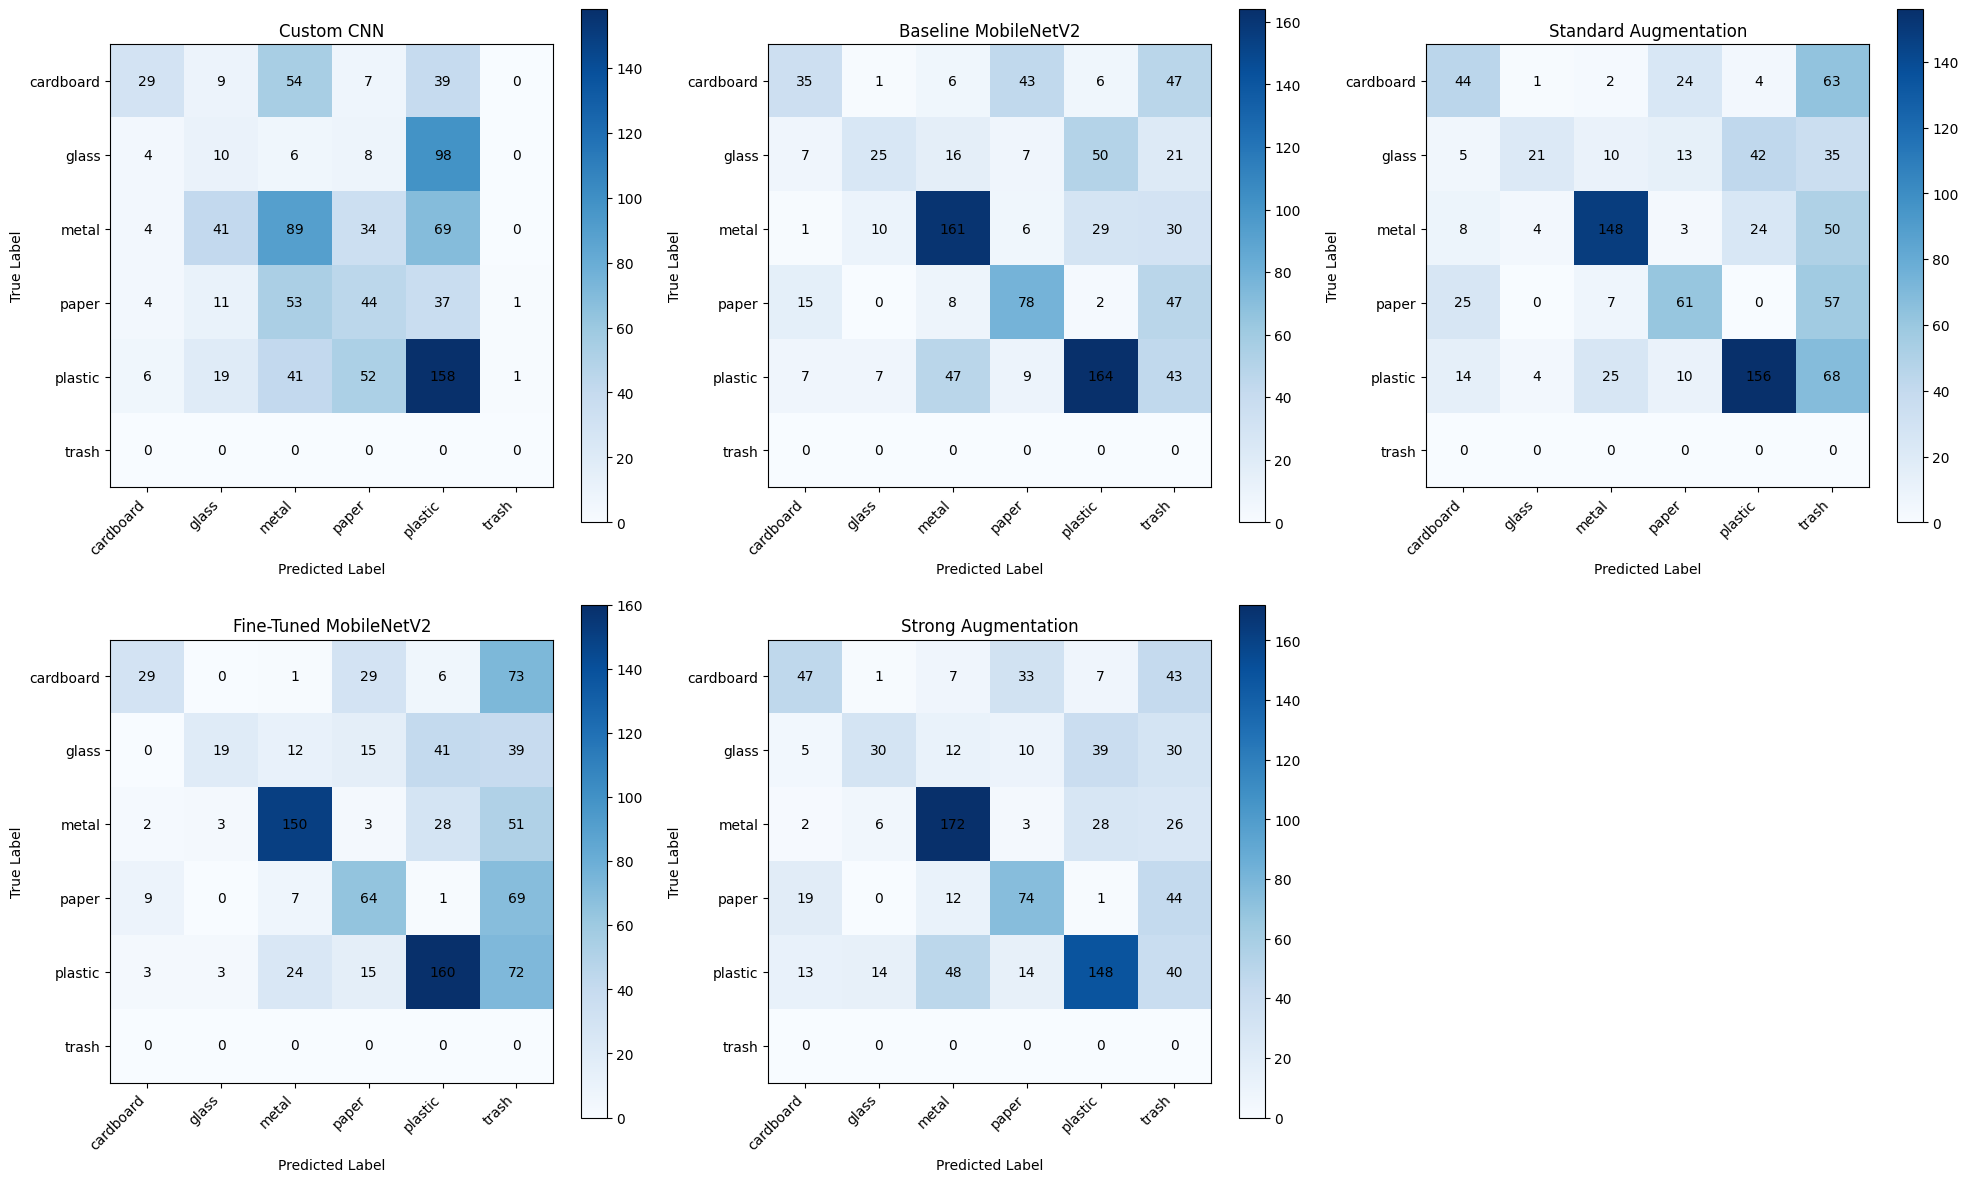

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

predictions = {
    "Custom CNN": y_pred_custom,
    "Baseline MobileNetV2": y_pred_mobilenet,
    "Standard Augmentation": y_pred_aug,
    "Fine-Tuned MobileNetV2": y_pred_finetune,
    "Strong Augmentation": y_pred_strong
}

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_real_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    im = axes[i].imshow(cm, cmap="Blues")

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

    axes[i].set_xticks(range(len(class_names)))
    axes[i].set_yticks(range(len(class_names)))

    axes[i].set_xticklabels(class_names, rotation=45, ha="right")
    axes[i].set_yticklabels(class_names)

    for row in range(len(class_names)):
        for col in range(len(class_names)):
            axes[i].text(
                col, row, cm[row, col],
                ha="center", va="center"
            )

    fig.colorbar(im, ax=axes[i])

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Step 11.13 - Classification Reports for All Models

In [ ]:
predictions = {
    "Custom CNN": y_pred_custom,
    "Baseline MobileNetV2": y_pred_mobilenet,
    "Standard Augmentation": y_pred_aug,
    "Fine-Tuned MobileNetV2": y_pred_finetune,
    "Strong Augmentation": y_pred_strong
}

for model_name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(classification_report(
        y_real_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))


Custom CNN
              precision    recall  f1-score   support

   cardboard       0.62      0.21      0.31       138
       glass       0.11      0.08      0.09       126
       metal       0.37      0.38      0.37       237
       paper       0.30      0.29      0.30       150
     plastic       0.39      0.57      0.47       277
       trash       0.00      0.00      0.00         0

    accuracy                           0.36       928
   macro avg       0.30      0.25      0.26       928
weighted avg       0.37      0.36      0.34       928


Baseline MobileNetV2
              precision    recall  f1-score   support

   cardboard       0.54      0.25      0.34       138
       glass       0.58      0.20      0.30       126
       metal       0.68      0.68      0.68       237
       paper       0.55      0.52      0.53       150
     plastic       0.65      0.59      0.62       277
       trash       0.00      0.00      0.00         0

    accuracy                           0.50

Step 11.14 - Export Final Comparison Table

In [ ]:
comparison_realwaste.to_csv(
    "/content/RealWaste_Model_Comparison.csv",
    index=False
)

print("Comparison table saved successfully!")
print("File: RealWaste_Model_Comparison.csv")

Comparison table saved successfully!
File: RealWaste_Model_Comparison.csv


Step 11.15- Export Per-Class Classification Reports

In [ ]:
report_data = []

for model_name, y_pred in predictions.items():

    report = classification_report(
        y_real_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        report_data.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

class_report_df = pd.DataFrame(report_data)

class_report_df.to_csv(
    "/content/RealWaste_Classification_Reports.csv",
    index=False
)

print("Classification reports saved successfully!")
display(class_report_df.head(10))

Classification reports saved successfully!


,Model,Class,Precision,Recall,F1-score,Support
0,Custom CNN,cardboard,0.617021,0.210145,0.313514,138.0
1,Custom CNN,glass,0.111111,0.079365,0.092593,126.0
2,Custom CNN,metal,0.366255,0.375527,0.370833,237.0
3,Custom CNN,paper,0.303448,0.293333,0.298305,150.0
4,Custom CNN,plastic,0.394015,0.570397,0.466077,277.0
5,Custom CNN,trash,0.000000,0.000000,0.000000,0.0
6,Baseline MobileNetV2,cardboard,0.538462,0.253623,0.344828,138.0
7,Baseline MobileNetV2,glass,0.581395,0.198413,0.295858,126.0
8,Baseline MobileNetV2,metal,0.676471,0.679325,0.677895,237.0
9,Baseline MobileNetV2,paper,0.545455,0.520000,0.532423,150.0


Step 11.16 - Save Confusion Matrices

In [ ]:
fig.savefig(
    "/content/RealWaste_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)

print("Confusion matrices saved successfully!")
print("File: RealWaste_Confusion_Matrices.png")

Confusion matrices saved successfully!
File: RealWaste_Confusion_Matrices.png


Step 11.17 - Save All Five Trained Models

In [ ]:
custom_cnn.save("/content/custom_cnn.keras")

mobilenet_model.save("/content/baseline_mobilenetv2.keras")

mobilenet_standard.save(
    "/content/standard_augmentation_mobilenetv2.keras"
)

mobilenet_finetune.save(
    "/content/finetuned_mobilenetv2.keras"
)

mobilenet_strong.save(
    "/content/strong_augmentation_mobilenetv2.keras"
)

print("All five model files saved successfully!")

All five model files saved successfully!


Step 11.18 - Verify All Five Saved Models

In [ ]:
import os

model_files = [
    "custom_cnn.keras",
    "baseline_mobilenetv2.keras",
    "standard_augmentation_mobilenetv2.keras",
    "finetuned_mobilenetv2.keras",
    "strong_augmentation_mobilenetv2.keras"
]

for file in model_files:
    path = "/content/" + file
    print(file, " - ", "Saved" if os.path.exists(path) else "Not Found")

custom_cnn.keras  -  Saved
baseline_mobilenetv2.keras  -  Saved
standard_augmentation_mobilenetv2.keras  -  Saved
finetuned_mobilenetv2.keras  -  Saved
strong_augmentation_mobilenetv2.keras  -  Saved


Step 11.19 – Create a Final Results Folder

In [ ]:
import os
import shutil

final_folder = "/content/Final_Research_Results"
os.makedirs(final_folder, exist_ok=True)

files_to_copy = [
    "RealWaste_Model_Comparison.csv",
    "RealWaste_Classification_Reports.csv",
    "RealWaste_Confusion_Matrices.png",
    "custom_cnn.keras",
    "baseline_mobilenetv2.keras",
    "standard_augmentation_mobilenetv2.keras",
    "finetuned_mobilenetv2.keras",
    "strong_augmentation_mobilenetv2.keras"
]

for file in files_to_copy:
    source = "/content/" + file
    if os.path.exists(source):
        shutil.copy(source, final_folder)
        print("Copied:", file)
    else:
        print("Not Found:", file)

print("\nFinal research folder created successfully!")

Copied: RealWaste_Model_Comparison.csv
Copied: RealWaste_Classification_Reports.csv
Copied: RealWaste_Confusion_Matrices.png
Copied: custom_cnn.keras
Copied: baseline_mobilenetv2.keras
Copied: standard_augmentation_mobilenetv2.keras
Copied: finetuned_mobilenetv2.keras
Copied: strong_augmentation_mobilenetv2.keras

Final research folder created successfully!


Step 11.20 – Download the Final Research Results Folder

In [ ]:
import shutil

shutil.make_archive(
    "/content/Final_Research_Results",
    "zip",
    "/content/Final_Research_Results"
)

print("Final research ZIP created successfully!")

Final research ZIP created successfully!


Step 11.21 – Download Final Research ZIP

In [ ]:
from google.colab import files

files.download("/content/Final_Research_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>